In [ ]:
import sqlite3

import pandas as pd
from crossfiledialog import open_file

### **Open the `index.db` and read table `images` as pandas data frame**

In [ ]:
index_db_path = open_file()

In [ ]:
conn = sqlite3.connect(index_db_path)
df = pd.read_sql_query("SELECT * FROM images", conn)

In [8]:
df.head()

,id,origin,fullname,name,format,size,width,height,created,modified,rating,tags,hash,color_1,color_2,color_3,color_4
0,1,/mnt/LOCAL/Resources/Fixtures/xs/img-0.jpg,img-0.jpg,img-0,JPG,107955,852,1280,1793308724630,1793131432600,0,,252b290ac7b557fc1099a860cac0c5738ac0521086ba24...,428761,14007211,1118481,6709088
1,2,/mnt/LOCAL/Resources/Fixtures/xs/img-1.jpg,img-1.jpg,img-1,JPG,759130,1706,2560,1793308731640,1793131470040,0,,90c960ab2d6135ba6fca20440ae7eb53f36c468723bf48...,593958,9212041,4608859,13945803
2,3,/mnt/LOCAL/Resources/Fixtures/xs/img-2.jpg,img-2.jpg,img-2,JPG,490175,853,1138,1793308731640,1751980468000,0,,9ebb25ff04840ef216174a40d7f2a4c1a685a253538c60...,10061685,13481629,3750200,263173
3,4,/mnt/LOCAL/Resources/Fixtures/xs/img-3.jpg,img-3.jpg,img-3,JPG,808813,1920,2560,1793308731640,1793116995290,0,,ada21d92bd07c446292786c30fbd1a9698d78056801fcb...,13751444,9470829,6839116,2696227


In [6]:
df.dtypes

id          int64
origin        str
fullname      str
name          str
format        str
size        int64
width       int64
height      int64
created     int64
modified    int64
rating      int64
tags          str
hash          str
color_1     int64
color_2     int64
color_3     int64
color_4     int64
dtype: object

# **EDA 👀**

In [ ]:
# Do whatever you want
# More cool more fun!
# Graph, diagram, etc... :>> play with data!

/mnt/DEV/Projects/FwLKhW/Eyeris/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


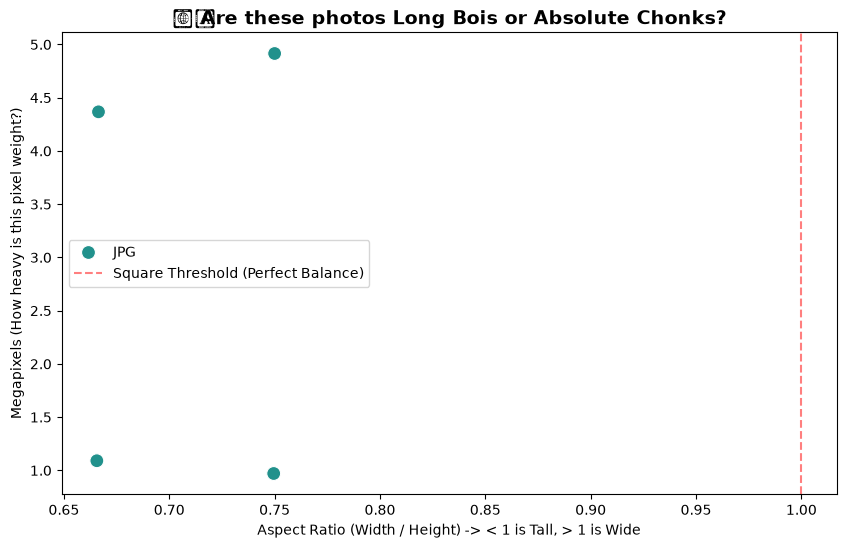

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

⏳ Chronological Time Travel Report:
Earliest creation date found: 2026-10-29 21:18:44.630000
Latest creation date found: 2026-10-29 21:18:51.640000
✨ Conclusion: Your photos were time-stamped by time travelers from the 57th century.


/mnt/DEV/Projects/FwLKhW/Eyeris/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


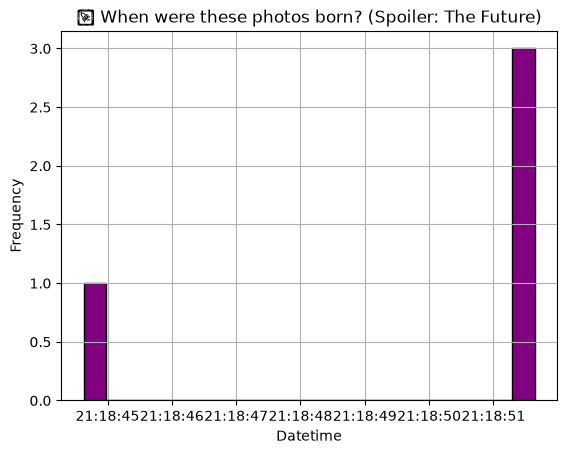

In [10]:
# Convert epoch milliseconds to datetime
df['created_dt'] = pd.to_datetime(df['created'], unit='ms')
df['modified_dt'] = pd.to_datetime(df['modified'], unit='ms')

print("⏳ Chronological Time Travel Report:")
print(f"Earliest creation date found: {df['created_dt'].min()}")
print(f"Latest creation date found: {df['created_dt'].max()}")
print("✨ Conclusion: Your photos were time-stamped by time travelers from the 57th century.")

# Plot creation timeline
df['created_dt'].hist(bins=20, color='purple', edgecolor='black')
plt.title("🚀 When were these photos born? (Spoiler: The Future)", fontsize=12)
plt.xlabel("Datetime")
plt.ylabel("Frequency")
plt.show()

👑 The Absolute Chonker Award goes to: img-3.jpg
   Size: 0.77 MB | Resolution: 1920x2560


/mnt/DEV/Projects/FwLKhW/Eyeris/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127828 (\N{HAMBURGER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


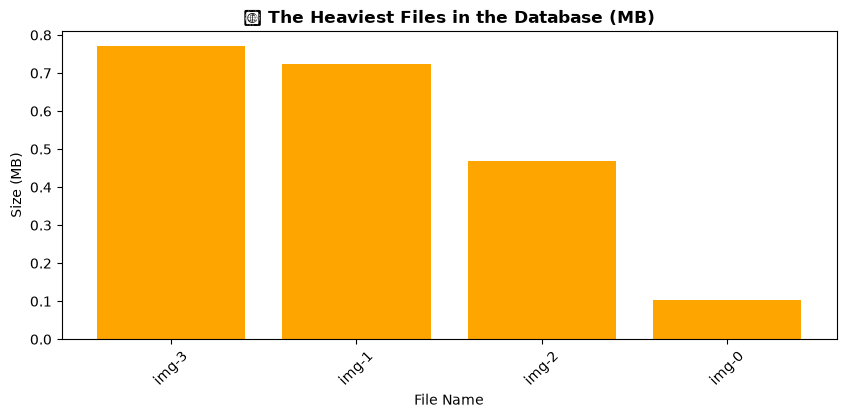

In [11]:
df['bytes_per_mp'] = df['size'] / df['megapixels']

# Find the biggest chonker
chonker = df.loc[df['size'].idxmax()]
print(f"👑 The Absolute Chonker Award goes to: {chonker['fullname']}")
print(f"   Size: {chonker['size'] / 1024 / 1024:.2f} MB | Resolution: {chonker['width']}x{chonker['height']}")

# Quick bar plot of top 10 heaviest files
top_heavy = df.nlargest(10, 'size')
plt.figure(figsize=(10, 4))
plt.bar(top_heavy['name'], top_heavy['size'] / 1024 / 1024, color='orange')
plt.title("🍔 The Heaviest Files in the Database (MB)", fontsize=12, fontweight='bold')
plt.xlabel("File Name")
plt.ylabel("Size (MB)")
plt.xticks(rotation=45)
plt.show()

In [12]:
rating_counts = df['rating'].value_counts()
print("⭐ Rating Breakdown:")
print(rating_counts)

if (df['rating'] == 0).all():
    print("💀 Brutal honesty detected: Every single image has a 0 rating. Tough crowd!")
else:
    print("🎉 Some images actually passed the vibe check and got rated!")

⭐ Rating Breakdown:
rating
0    4
Name: count, dtype: int64
💀 Brutal honesty detected: Every single image has a 0 rating. Tough crowd!
